In [1]:
import time
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

X_train = pd.read_csv("../data/X_train.csv")
y_train = pd.read_csv("../data/y_train.csv")["Class"]

spw = (y_train == 0).sum() / (y_train == 1).sum()
print("Genuine-to-fraud ratio:", round(spw, 1))

Genuine-to-fraud ratio: 599.5


In [2]:
models = {
    "LogReg + class_weight": LogisticRegression(
        max_iter=1000, class_weight="balanced", random_state=42),

    "LogReg + SMOTE": ImbPipeline([
        ("smote", SMOTE(random_state=42)),
        ("model", LogisticRegression(max_iter=1000, random_state=42)),
    ]),

    "Random Forest": RandomForestClassifier(
        n_estimators=100, n_jobs=-1, random_state=42),

    "XGBoost": XGBClassifier(
        n_estimators=300, learning_rate=0.1, max_depth=6,
        eval_metric="aucpr", n_jobs=-1, random_state=42),

    "XGBoost + weight": XGBClassifier(
        n_estimators=300, learning_rate=0.1, max_depth=6,
        scale_pos_weight=spw, eval_metric="aucpr", n_jobs=-1, random_state=42),
}

In [3]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    "PR-AUC": "average_precision",
    "ROC-AUC": "roc_auc",
    "Recall": "recall",
    "Precision": "precision",
    "F1": "f1",
}

rows = []
for name, model in models.items():
    start = time.time()
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring)
    row = {"Model": name}
    for metric in scoring:
        row[metric] = scores[f"test_{metric}"].mean()
    row["PR-AUC std"] = scores["test_PR-AUC"].std()
    row["Time (s)"] = round(time.time() - start)
    rows.append(row)
    print(f"{name:25} PR-AUC = {row['PR-AUC']:.4f} ± {row['PR-AUC std']:.4f}  ({row['Time (s)']}s)")

LogReg + class_weight     PR-AUC = 0.7544 ± 0.0271  (9s)
LogReg + SMOTE            PR-AUC = 0.7516 ± 0.0279  (19s)
Random Forest             PR-AUC = 0.8339 ± 0.0306  (167s)
XGBoost                   PR-AUC = 0.8424 ± 0.0272  (22s)
XGBoost + weight          PR-AUC = 0.8454 ± 0.0257  (24s)


,PR-AUC,ROC-AUC,Recall,Precision,F1,PR-AUC std,Time (s)
Model,,,,,,,
XGBoost + weight,0.8454,0.9814,0.8280,0.9121,0.8667,0.0257,24
XGBoost,0.8424,0.9787,0.7776,0.9470,0.8527,0.0272,22
Random Forest,0.8339,0.9402,0.7751,0.9396,0.8477,0.0306,167
LogReg + class_weight,0.7544,0.9819,0.9073,0.0575,0.1081,0.0271,9
LogReg + SMOTE,0.7516,0.9817,0.9073,0.0555,0.1046,0.0279,19


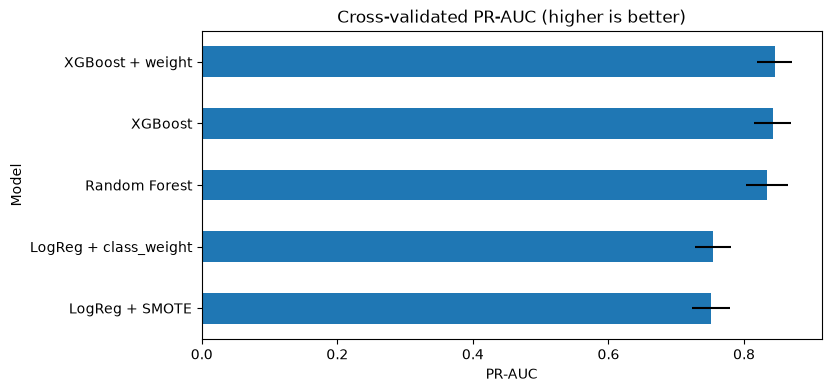

In [4]:
cv_table = pd.DataFrame(rows).set_index("Model").sort_values("PR-AUC", ascending=False).round(4)
display(cv_table)

cv_table["PR-AUC"].plot.barh(xerr=cv_table["PR-AUC std"], figsize=(8, 4),
                             title="Cross-validated PR-AUC (higher is better)")
plt.gca().invert_yaxis()
plt.xlabel("PR-AUC")
plt.show()

In [5]:
best_name = cv_table["PR-AUC"].idxmax()
print("Best model:", best_name)

best_model = models[best_name]
best_model.fit(X_train, y_train)

joblib.dump(best_model, "../models/best_model.pkl")
print("Saved to models/best_model.pkl")

Best model: XGBoost + weight
Saved to models/best_model.pkl


## Findings (5-fold stratified CV, training data only)
- Tree models beat Logistic Regression clearly: PR-AUC ~0.84 vs ~0.75.
- XGBoost + scale_pos_weight is best: PR-AUC 0.845 ± 0.026, recall 0.83, precision 0.91, F1 0.87.
- LogReg has the highest ROC-AUC (0.982) but precision of only 0.06 → ROC-AUC is misleading on imbalanced data; PR-AUC is the better metric.
- Differences among the top 3 are within one standard deviation; XGBoost + weight chosen for best PR-AUC, recall, stability, and speed (24s vs 167s for Random Forest).